# Lab assignment №1, part 3

This lab assignment consists of several parts. You are supposed to make some transformations, train some models, estimate the quality of the models and explain your results.

Several comments:
* Don't hesitate to ask questions, it's a good practice.
* No private/public sharing, please. The copied assignments will be graded with 0 points.
* Blocks of this lab will be graded separately.

__*This is the third part of the assignment. First and second parts are waiting for you in the same directory.*__

##  Part 3. SVM and kernels

Kernels concept get adopted in variety of ML algorithms (e.g. Kernel PCA, Gaussian Processes, kNN, ...).

So in this task you are to examine kernels for SVM algorithm applied to rather simple artificial datasets.

To make it clear: we will work with the classification problem through the whole notebook. 

In [1]:
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
import numpy as np

Let's generate our dataset and take a look on it.

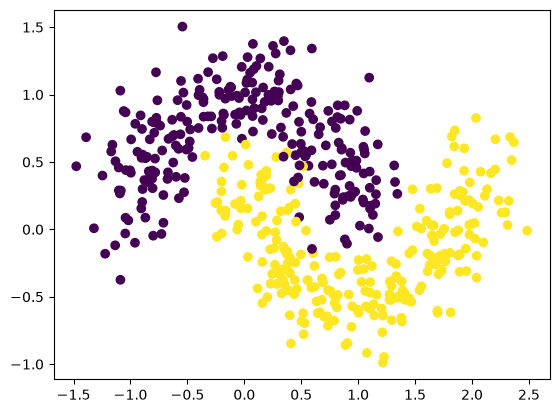

In [2]:
moons_points, moons_labels = make_moons(n_samples=500, noise=0.2, random_state=42)
plt.scatter(moons_points[:, 0], moons_points[:, 1], c=moons_labels)

## 1.1 Pure models.
First let's try to solve this case with good old Logistic Regression and simple (linear kernel) SVM classifier.

Train LR and SVM classifiers (choose params by hand, no CV or intensive grid search neeeded) and plot their decision regions. Calculate one preffered classification metric.

Describe results in one-two sentences.

_Tip:_ to plot classifiers decisions you colud use either sklearn examples ([this](https://scikit-learn.org/stable/auto_examples/neural_networks/plot_mlp_alpha.html#sphx-glr-auto-examples-neural-networks-plot-mlp-alpha-py) or any other) and mess with matplotlib yourself or great [mlxtend](https://github.com/rasbt/mlxtend) package (see their examples for details)

_Pro Tip:_ wirte function `plot_decisions` taking a dataset and an estimator and plotting the results cause you want to use it several times below

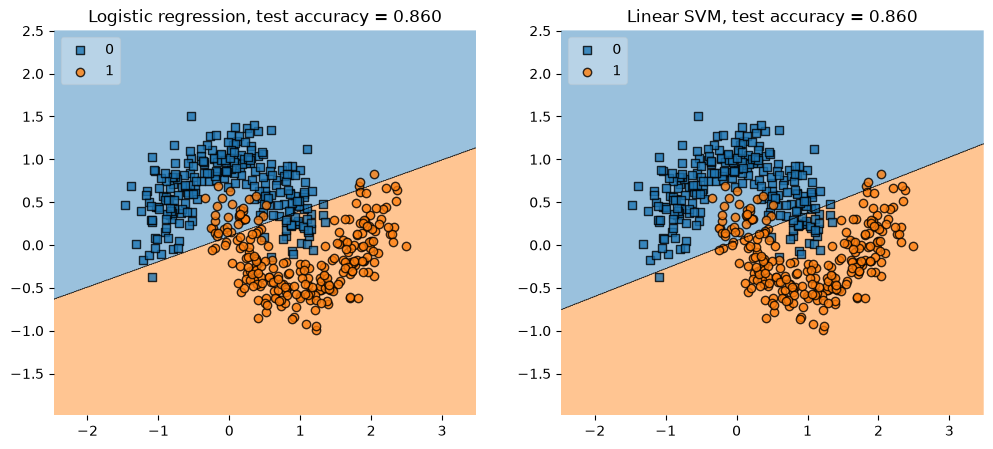

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score

from mlxtend.plotting import plot_decision_regions

X_train, X_test, y_train, y_test = train_test_split(
    moons_points, moons_labels, test_size=0.3, random_state=42, stratify=moons_labels
)


def plot_decisions(models, X, y, X_test, y_test, ncols=2):
    nrows = int(np.ceil(len(models) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows), squeeze=False)
    for ax, (name, model) in zip(axes.ravel(), models.items()):
        plot_decision_regions(X, y, clf=model, legend=2, ax=ax, markers='so^v')
        acc = accuracy_score(y_test, model.predict(X_test))
        ax.set_title(f'{name}, test accuracy = {acc:.3f}')
    for ax in axes.ravel()[len(models):]:
        ax.axis('off')
    plt.show()


lr = LogisticRegression(C=1.0)
svm = SVC(kernel='linear', C=1.0)
lr.fit(X_train, y_train)
svm.fit(X_train, y_train)

plot_decisions({'Logistic regression': lr, 'Linear SVM': svm}, moons_points, moons_labels, X_test, y_test)

Делю выборку на train и test (70/30). Метрика accuracy: классы сбалансированы, по 250 точек. Параметры оставил простыми, C = 1.

Обе модели строят прямую границу и дают одинаковую accuracy 0.86. Прямой два вложенных полумесяца не разделить, ошибки на концах лун, которые заходят друг под друга.

## 1.2 Kernel tirck

Now use different kernels (`poly`, `rbf`, `sigmoid`) on SVC to get better results. Play `degree` parameter and others.

For each kernel estimate optimal params, plot decision regions, calculate metric you've chosen eariler.

Write couple of sentences on:

* What have happenned with classification quality?
* How did decision border changed for each kernel?
* What `degree` have you chosen and why?

poly {'C': 100, 'coef0': 1, 'degree': 3} cv accuracy: 0.98
rbf {'C': 10, 'gamma': 2} cv accuracy: 0.977


sigmoid {'C': 10, 'coef0': -1, 'gamma': 0.1} cv accuracy: 0.866


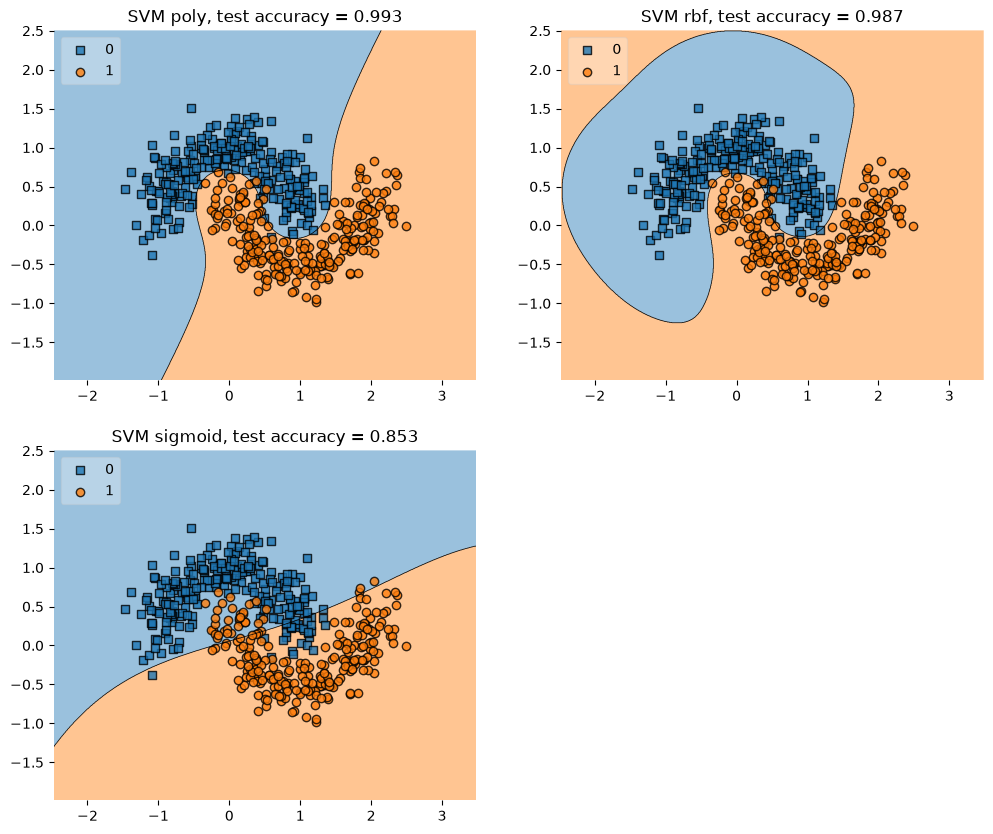

poly, coef0=1, C=10, cv accuracy by degree: [0.863 0.86  0.974 0.974 0.971 0.974 0.977]


In [4]:
kernel_grids = {
    'poly': {'degree': [2, 3, 4, 5], 'coef0': [0, 1], 'C': [0.1, 1, 10, 100]},
    'rbf': {'C': [0.1, 1, 10, 100], 'gamma': [0.1, 0.5, 1, 2, 5]},
    'sigmoid': {'C': [0.01, 0.1, 1, 10], 'gamma': [0.01, 0.1, 0.5, 1], 'coef0': [-1, 0, 1]},
}

kernel_models = {}
for kernel, grid in kernel_grids.items():
    search = GridSearchCV(SVC(kernel=kernel), grid, cv=5, scoring='accuracy')
    search.fit(X_train, y_train)
    kernel_models[f'SVM {kernel}'] = search.best_estimator_
    print(kernel, search.best_params_, 'cv accuracy:', round(search.best_score_, 3))

plot_decisions(kernel_models, moons_points, moons_labels, X_test, y_test)

poly_scores = GridSearchCV(SVC(kernel='poly', coef0=1, C=10), {'degree': [1, 2, 3, 4, 5, 6, 7]}, cv=5).fit(X_train, y_train)
print('poly, coef0=1, C=10, cv accuracy by degree:', np.round(poly_scores.cv_results_['mean_test_score'], 3))

Параметры подбирал через GridSearchCV на train.

- poly: degree = 3, coef0 = 1, C = 100, accuracy на тесте 0.99. Граница стала S-образной кривой, которая проходит между лунами.
- rbf: C = 10, gamma = 2, accuracy 0.99. Граница замкнутая: область класса 0 это "капля" вокруг верхней луны, всё остальное класс 1. RBF-ядро локальное, вдали от точек решение определяется только сдвигом.
- sigmoid: лучший результат 0.85, не лучше линейного SVM, граница почти прямая. Сигмоидное ядро здесь не помогает.

Качество выросло с 0.86 до 0.99 у poly и rbf.

degree выбирал по кросс-валидации: при coef0 = 1 степени 1 и 2 дают 0.86, начиная с 3 около 0.97, и дальше качество не растёт. Беру 3: это минимальная степень, при которой граница может изогнуться S-образно. Квадратичная граница (коника) так изогнуться не может. coef0 = 1 нужен, чтобы в ядре были все мономы степени до 3, а не только степени ровно 3.

## 1.3 Simpler solution (of a kind)
What is we could use Logisitc Regression to successfully solve this task?

Feature generation is a thing to help here. Different techniques of feature generation are used in real life, couple of them will be covered in additional lectures.

In particular case simple `PolynomialFeatures` ([link](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html)) are able to save the day.

Generate the set of new features, train LR on it, plot decision regions, calculate metric.

* Comare SVM's results with this solution (quality, borders type)
* What degree of PolynomialFeatures have you used? Compare with same SVM kernel parameter.

{'lr__C': 100, 'poly__degree': 3} cv accuracy: 0.974


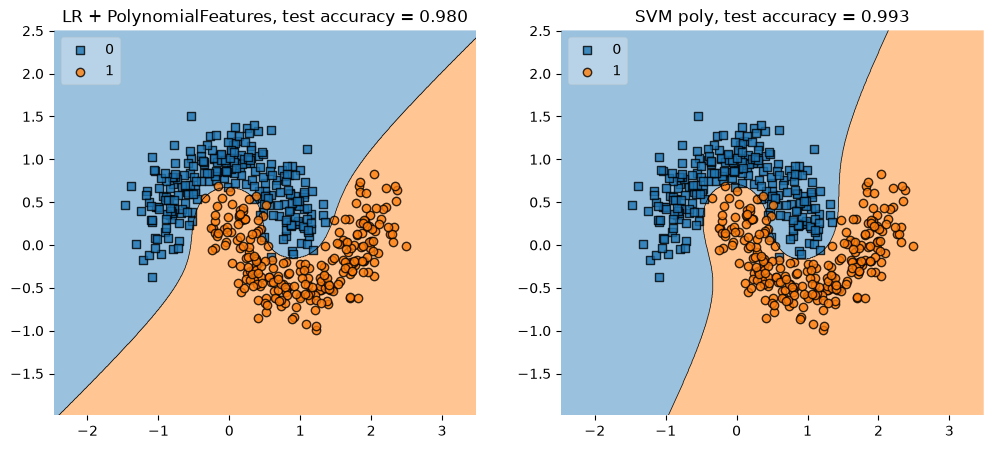

In [5]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline

poly_lr = Pipeline([
    ('poly', PolynomialFeatures()),
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(max_iter=5000)),
])
poly_search = GridSearchCV(
    poly_lr,
    {'poly__degree': [1, 2, 3, 4, 5, 6, 7], 'lr__C': [0.1, 1, 10, 100]},
    cv=5,
    scoring='accuracy',
)
poly_search.fit(X_train, y_train)
print(poly_search.best_params_, 'cv accuracy:', round(poly_search.best_score_, 3))

plot_decisions(
    {'LR + PolynomialFeatures': poly_search.best_estimator_, 'SVM poly': kernel_models['SVM poly']},
    moons_points, moons_labels, X_test, y_test,
)

PolynomialFeatures, потом стандартизация и логистическая регрессия. Степень и C подбирал по кросс-валидации, лучшие degree = 3 и C = 100.

Accuracy на тесте 0.98, у SVM с полиномиальным ядром 0.99. Граница почти такая же S-образная кривая.

Степень совпала с degree у SVM. Полиномиальное ядро степени 3 с coef0 = 1 это скалярное произведение в пространстве тех же мономов степени до 3. SVM работает с ними неявно через ядро, а здесь признаки строятся явно. Для 2 признаков это всего 10 признаков, так что явное построение дёшево. При большом числе признаков и высокой степени выгоднее ядро.

## 1.4 Harder problem

Let's make this task a bit more challenging via upgrading dataset:

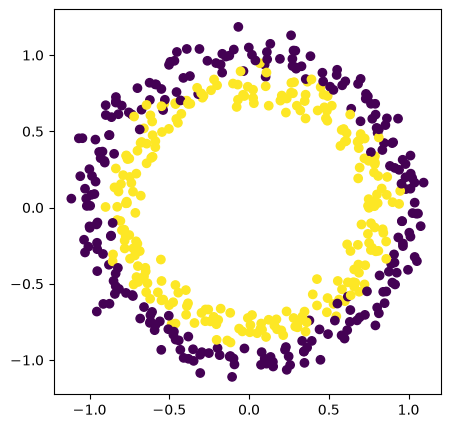

In [6]:
from sklearn.datasets import make_circles

circles_points, circles_labels = make_circles(n_samples=500, noise=0.06, random_state=42)

plt.figure(figsize=(5, 5))
plt.scatter(circles_points[:, 0], circles_points[:, 1], c=circles_labels)

And even more:

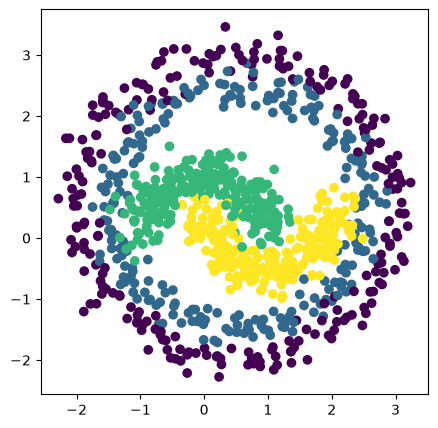

In [7]:
points = np.vstack((circles_points*2.5 + 0.5, moons_points))
labels = np.hstack((circles_labels, moons_labels + 2)) # + 2 to distinct moons classes

plt.figure(figsize=(5, 5))
plt.scatter(points[:, 0], points[:, 1], c=labels)

Now do your best using all the approaches above!

Tune LR with generated features, SVM with appropriate kernel of your choice. You may add some of your loved models to demonstrate their (and your) strength. Again plot decision regions, calculate metric.

Justify the results in a few phrases.

LR + PolynomialFeatures {'lr__C': 100, 'poly__degree': 4} cv accuracy: 0.937


SVM rbf {'C': 1, 'gamma': 5} cv accuracy: 0.934
kNN {'n_neighbors': 7} cv accuracy: 0.917


Random forest {'max_depth': 8} cv accuracy: 0.9


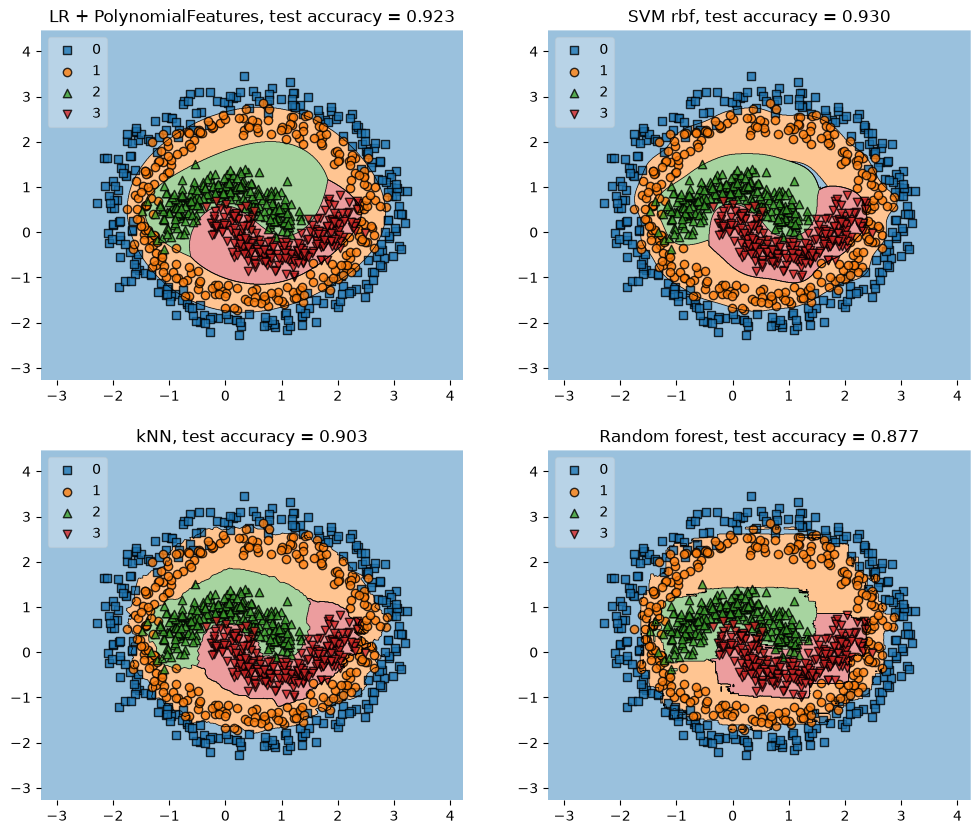

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

X_train, X_test, y_train, y_test = train_test_split(
    points, labels, test_size=0.3, random_state=42, stratify=labels
)

searches = {
    'LR + PolynomialFeatures': GridSearchCV(
        Pipeline([
            ('poly', PolynomialFeatures()),
            ('scaler', StandardScaler()),
            ('lr', LogisticRegression(max_iter=5000)),
        ]),
        {'poly__degree': [2, 3, 4, 5, 6], 'lr__C': [0.1, 1, 10, 100]},
        cv=5,
    ),
    'SVM rbf': GridSearchCV(
        SVC(kernel='rbf'),
        {'C': [0.1, 1, 10, 100], 'gamma': [0.1, 0.5, 1, 2, 5]},
        cv=5,
    ),
    'kNN': GridSearchCV(
        KNeighborsClassifier(),
        {'n_neighbors': [1, 3, 5, 7, 11, 15, 21]},
        cv=5,
    ),
    'Random forest': GridSearchCV(
        RandomForestClassifier(n_estimators=200, random_state=42),
        {'max_depth': [3, 5, 8, None]},
        cv=5,
    ),
}

hard_models = {}
for name, search in searches.items():
    search.fit(X_train, y_train)
    hard_models[name] = search.best_estimator_
    print(name, search.best_params_, 'cv accuracy:', round(search.best_score_, 3))

plot_decisions(hard_models, points, labels, X_test, y_test)

Делю так же 70/30, 4 класса по 250 точек, метрика accuracy.

- LR + PolynomialFeatures (degree = 4, C = 100): 0.92
- SVM rbf (C = 1, gamma = 5): 0.93
- kNN (k = 7): 0.90
- Random forest (max_depth = 8): 0.88

Кольца и луны вложены друг в друга, и границы должны быть замкнутыми. Полиномиальные признаки степени 4 и RBF-ядро это умеют, у них самые гладкие границы и лучшее качество. Лучшая модель SVM с RBF-ядром, логистическая регрессия на полиномиальных признаках почти не уступает. У kNN граница рваная. У леса граница ступенчатая, из отрезков, параллельных осям, поэтому кольца он описывает хуже всех.

Больше всего ошибок между внешним и внутренним кольцом (у SVM 13 из 21). После умножения на 2.5 радиусы колец 2.5 и 2, зазор 0.5, а шум 0.15, и точки колец заходят друг на друга. Так что 100% здесь не получить.